# 02. Default definition

**Goal:** decide what counts as a "default", and check that the default rate by loan year looks sensible.

**Why this matters:** the whole project depends on this rule. If the rule is wrong, every later result is wrong too.

**The draft rule (not final).** Time is counted in calendar months from the month of the loan's first payment (month 1 is that month). A loan counts as a **default** if, within its first 24 months, any of these happens:
- it is 90 or more days late in any month (delinquency status 3 or higher), even if it catches up later,
- the lender takes the property (status `RA`),
- the loan ends with zero balance code `03` (short sale or charge-off) or `09` (REO disposition).

Everything else is **not a default**. That includes a loan that is paid off early (code `01`) without ever being 90 days late, and the other ways a loan can end (codes `02`, `15`, `16` and `96`, see section 2). A loan with no default, still active and watched for less than 24 months has an unknown outcome and would be dropped (none in this data).

**Why calendar months and not the "loan age" column?** An earlier version of this notebook used the loan-age column. Loan age restarts after a loan modification, so for modified loans a default that happened years later could still look like it fell inside "24 months". Section 4 shows how much this mattered.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent          # this notebook lives in notebooks/
# so I can import from src/
sys.path.insert(0, str(ROOT / "src"))
from check_default_rates import vintage_summary
from compare_default_rules import compare_year

RAW = ROOT / "data" / "raw"
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

## 1. What do the raw files look like?

There are two files per year. The **origination file** has one row per loan (who borrowed, how much, on what terms). The **performance file** has one row per loan **per month** (balance, how late the payments are). They are linked by the loan identifier. The files have no header, so column names have to come from the Freddie Mac documents.

In [2]:
# a few rows, only the columns I use (0 credit score, 1 first payment date, 10 balance, 12 rate, 16 state, 19 id)
orig = pd.read_csv(RAW / "sample_orig_2002.txt", sep="|", header=None, nrows=3, dtype=str)
print("Origination file: 31 columns, counted from 0. Column 1 is the first payment date, column 19 is the loan identifier.")
orig.iloc[:, [0, 1, 10, 12, 16, 19]]

Origination file: 31 columns, counted from 0. Column 1 is the first payment date, column 19 is the loan identifier.


,0,1,10,12,16,19
0,780,200204,60000,6.625,OR,F02Q10000115
1,648,200203,181000,7,WA,F02Q10000139
2,675,200204,125000,6.5,WA,F02Q10000141


In [3]:
# first months of one loan, with readable names
perf = pd.read_csv(RAW / "sample_perf_2002.txt", sep="|", header=None, nrows=6, dtype=str)
perf = perf.iloc[:, [0, 1, 2, 3, 4, 8]]
perf.columns = ["loan_id", "month", "balance", "delinquency_status", "loan_age", "zero_balance_code"]
print("Performance file: 35 columns. These are the six I look at here.")
perf

Performance file: 35 columns. These are the six I look at here.


,loan_id,month,balance,delinquency_status,loan_age,zero_balance_code
0,F02Q10000115,200203,60000.00,00,0,NaN
1,F02Q10000115,200204,60000.00,00,1,NaN
2,F02Q10000115,200205,60000.00,00,2,NaN
3,F02Q10000115,200206,60000.00,00,3,NaN
4,F02Q10000115,200207,59000.00,00,4,NaN
5,F02Q10000115,200208,59000.00,00,5,NaN


## 2. The codes I am using

- **Delinquency status:** `00` = current, `01` = 30-59 days late, `02` = 60-89, `03` = 90-119, and so on up to `99`. `RA` = the lender took the property, `XX` = not available.
- **Zero balance code** (why the loan ended): `01` = paid off, `02` = third-party sale, `03` = short sale or charge-off, `09` = REO disposition, `15` = whole loan sale, `16` = reperforming loan securitization, `96` = underwriting or servicing defect before any credit event.

These come from the Freddie Mac user guide. In the draft rule only `03` and `09` count as a default. That is my judgement: `01` is a prepayment, and `02`, `15`, `16` and `96` are other ways a loan can end. Counting `02` as well changes none of the rates here (see the column `default_rate_with_code02_%` in section 3). Below I check which values really appear in the 2002 data.

In [4]:
# which values really occur for these two codes?
cols = pd.read_csv(RAW / "sample_perf_2002.txt", sep="|", header=None, usecols=[3, 8], dtype=str)
print("Delinquency status values (every loan-month):")
print(cols[3].value_counts().head(12).rename_axis("status").rename("loan-months").to_string())
print()
print("Zero balance codes (only the month a loan ends):")
print(cols[8].value_counts().rename_axis("code").rename("loans").to_string())

Delinquency status values (every loan-month):
status
00    2424292
01      37540
02       9656
03       3977
RA       3760
04       2599
05       2229
06       1715
07       1376
08       1143
09        991
10        858

Zero balance codes (only the month a loan ends):
code
01    48792
09      487
96      135
16      114
02      108
03       52
15       23


## 3. Default rate for each loan year (calendar rule)

For each year I count how many of the 50,000 loans in the sample meet the draft rule. I also count loans whose result is still unknown (not defaulted, still active, and watched for less than 24 months). Those would have to be dropped.

In [5]:
# default rate per year, the rule is in src/check_default_rates.py
rows = [vintage_summary(y) for y in range(2002, 2008)]
summary = pd.DataFrame(rows).set_index("vintage")
summary

,orig_loans,orig_ids_in_perf_%,outcome_unknown_dropped,kept,defaults,default_rate_%,default_rate_with_code02_%,modified_loans_%
vintage,,,,,,,,
2002,50000,100.0,0,50000,437,0.87,0.87,0.66
2003,50000,100.0,0,50000,216,0.43,0.43,1.08
2004,50000,100.0,0,50000,395,0.79,0.79,2.05
2005,50000,100.0,0,50000,526,1.05,1.05,3.67
2006,50000,100.0,0,50000,968,1.94,1.94,5.18
2007,50000,100.0,0,50000,2449,4.90,4.90,6.16


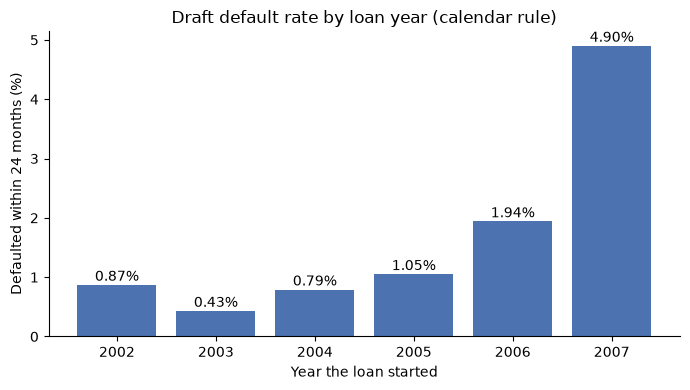

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(summary.index.astype(str), summary["default_rate_%"], color="#4C72B0")
# label each bar
for x, v in zip(summary.index.astype(str), summary["default_rate_%"]):
    ax.text(x, v + 0.07, f"{v:.2f}%", ha="center")
ax.set_xlabel("Year the loan started")
ax.set_ylabel("Defaulted within 24 months (%)")
ax.set_title("Draft default rate by loan year (calendar rule)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
# save the chart
(ROOT / "results" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT / "results" / "figures" / "default_rate_by_vintage.png", dpi=150)
plt.show()

## 4. Why not the loan-age column? A comparison

Same default event, same 24-month window. The only difference is how the 24 months are counted: by the **loan-age column** (rule A) or by **calendar months since the first payment** (rule C).

In [7]:
# old rule (loan age) against new rule (calendar months)
cmp_rows = [compare_year(y) for y in range(2002, 2008)]
comparison = pd.DataFrame(cmp_rows).set_index("vintage")[
    ["rate_A_age_%", "rate_C_calendar_%", "loans_where_rules_differ", "...of which modified",
     "modified_loans_%", "rate_C_modified_loans_%", "rate_C_unmodified_loans_%"]]
comparison

,rate_A_age_%,rate_C_calendar_%,loans_where_rules_differ,...of which modified,modified_loans_%,rate_C_modified_loans_%,rate_C_unmodified_loans_%
vintage,,,,,,,
2002,1.07,0.87,100,100,0.66,15.4,0.78
2003,0.77,0.43,170,170,1.08,6.7,0.36
2004,1.47,0.79,342,342,2.05,6.5,0.67
2005,2.13,1.05,540,540,3.67,6.1,0.86
2006,3.44,1.94,751,751,5.18,11.0,1.44
2007,6.19,4.90,644,643,6.16,29.0,3.31


## 5. What I see

- With the calendar rule the default rate is low for loans started in 2002-2004 (about 0.4% to 0.9%), in the middle for 2005 (about 1.1%), and climbs in 2006 (about 1.9%) and 2007 (about 4.9%). So the plan of training on calm years and testing on stressed years still looks sensible, and 2007 is about six times 2004.
- The loan-age rule gave higher rates (for example 2.13% instead of 1.05% for 2005). Almost every loan where the two rules disagree was modified. After a modification the loan age restarts, so later defaults looked like early ones. The calendar rule avoids this.
- Modified loans default far more often than other loans (roughly 6% to 29% against 0.4% to 3.3%), and they are a larger share in later years (about 0.7% of the 2002 loans, 6% of the 2007 loans). A modification often follows trouble, so I still need to decide how to treat modified loans.
- Every loan in the origination file appears in the performance file, and no loans had to be dropped for an unknown outcome.

**Cautions**
- **This rule is a draft.** I still need the official Freddie Mac file layout to confirm every column and code, and then I must settle the rule for good.
- **Modified loans are not settled.** A modification often follows trouble, and these loans default far more often than the rest. I have not decided whether to treat a modification itself as a warning sign or to handle these loans separately.
- **Prepaid loans count as "not defaulted".** A loan that is paid off early cannot default afterwards. This is a simplification.
- **The year-to-year differences are not noise, but the calm years have few defaults.** Each year has 50,000 loans, so a rate is accurate to about 0.2 percentage points or better (for example 0.43% plus or minus 0.06, and 4.90% plus or minus 0.19). The calm years, however, contain few defaults (437 in 2002, 216 in 2003, 395 in 2004, about 1,050 in all), which is thin for training a model.
- **The sample may not represent all Freddie Mac loans of that year.** I have not checked this.
- **This is a sanity check, not a result.**